In [39]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.gridspec as gridspec
import f90nml
import dispatch_utils as du
from dusty_box import dusty_box
import itertools

In [3]:
def read_nml(iout, datadir='../data', verbose=False):
    import os

    snapdir = datadir + '/' + "{:05d}".format(iout)
    files = [f for f in os.listdir(snapdir) if f.endswith('snapshot.nml')]
    for f in files:
        if verbose:
            print('parsing',snapdir)
        nml_list = f90nml.read(snapdir+'/'+f)

    idx_dict = {}
    for k,v in nml_list['idx_nml'].items():
        idx_dict[k] = v

    return nml_list, idx_dict

def relative_difference(A,B):

    return np.abs((A-B)/A)

In [101]:
# turn on interactive plotting
plt.interactive(True)
# set font style and size
plt.rc('text', usetex=True)
plt.rc('font', **{'family':'serif','serif':['Computer Modern Roman']})
plt.rc('figure',figsize = (8.0,9.0))
plt.rc('font', size = 18)

In [105]:
# parameters
istart = 0
iend = 20
t_end = 2.0
datadir = '../data'
runs = ['linear','quadratic','power','third_order','mixed']

In [110]:
s_nmls = dict()
vx_dust_values = dict()
times = dict()
Kdrag_values = dict()
pindex_values = dict()
# read in the data
for r in runs:
    c_s_nmls = []
    c_vx_dust_values = []
    c_times = []
    rundir = 'input_'+r
    first_time = True
    for i in range(istart,iend+1):
        # read snapshot namelist
        s_nml, idx = read_nml(i,datadir=datadir+'/'+rundir,verbose=False)
        c_s_nmls.append(s_nml)
        if first_time:
            ndust = s_nml['force_params']['nc']
            drag_regime = s_nml['force_params']['drag'].strip()
            vx_gas0 = s_nml['experiment_params']['vx']
            vx_dust0 = s_nml['experiment_params']['vx2']
            d_gas0 = s_nml['experiment_params']['rho']
            d_dust0 = s_nml['experiment_params']['rho2']
            Kdrag = s_nml['force_params']['k']
            pindex = s_nml['force_params']['b']
            Kdrag_values[r] = Kdrag
            pindex_values[r] = pindex
            first_time = False
        snap = du.snapshot(iout=i,data=datadir+'/'+rundir)
        p0 = snap.patches[0]
        
        c_times.append(p0.time)
        # determine array index of dust density and x-velocity
        idx_offset = int(s_nml['snapshot_nml']['nv']/ndust)
        idx_d_dust = idx['d'] + idx_offset
        idx_px_dust = idx['px'] + idx_offset
        imid = int((p0.ui[0] + p0.li[0])/2)
        gmin, gmax = 1.0e32, -1.0e32
        for p in snap.patches:
            vx_dust = p.data[:,0,0,idx_px_dust]/p.data[:,0,0,idx_d_dust]
            gmin, gmax = min(gmin,np.min(vx_dust)), max(gmax,np.max(vx_dust))
        print("ID:",p0.id,"; t =",p0.time,"; no. patches:",len(snap.patches),"data dir:",datadir+'/'+rundir,"; vx_dust min:",gmin,"max:",gmax)
        vx_dust = p0.data[:,0,0,idx_px_dust]/p0.data[:,0,0,idx_d_dust]
        c_vx_dust_values.append(vx_dust[imid])

    s_nmls[r] = c_s_nmls
    vx_dust_values[r] = c_vx_dust_values
    times[r] = c_times

ID: 1 ; t = 0.0 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 1.0 max: 1.0
ID: 1 ; t = 0.1 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.9093879 max: 0.9093879
ID: 1 ; t = 0.2 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.8351923 max: 0.8351923
ID: 1 ; t = 0.3 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.7744406 max: 0.7744406
ID: 1 ; t = 0.4 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.72469807 max: 0.72469807
ID: 1 ; t = 0.5 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.68397015 max: 0.68397015
ID: 1 ; t = 0.6 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.650624 max: 0.650624
ID: 1 ; t = 0.7 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.62332183 max: 0.62332183
ID: 1 ; t = 0.8 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust min: 0.600968 max: 0.600968
ID: 1 ; t = 0.9 ; no. patches: 5 data dir: ../data/input_linear ; vx_dust 

ID: 1 ; t = 0.6 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.590795 max: 0.590795
ID: 1 ; t = 0.7 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.57337743 max: 0.57337743
ID: 1 ; t = 0.8 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.559561 max: 0.559561
ID: 1 ; t = 0.9 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.54848504 max: 0.54848504
ID: 1 ; t = 1.0 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.53954464 max: 0.53954464
ID: 1 ; t = 1.1 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.53229386 max: 0.53229386
ID: 1 ; t = 1.2 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.5263948 max: 0.5263948
ID: 1 ; t = 1.3 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.52158535 max: 0.52158535
ID: 1 ; t = 1.4 ; no. patches: 5 data dir: ../data/input_mixed ; vx_dust min: 0.51765895 max: 0.51765895
ID: 1 ; t = 1.5 ; no. patches: 5 data dir: ../data/input_mixed ; 

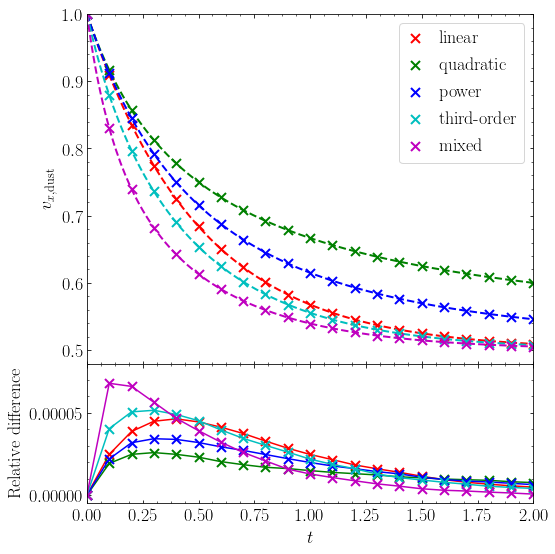

In [109]:
# plot the results and relative differences w.r.t. the analytical solution
fig = plt.figure(1)
fig.clf()
gs = fig.add_gridspec(ncols=1,nrows=2,height_ratios=[2.5,1],hspace=0.0)
cax1 = fig.add_subplot(gs[0,0])
cax2 = fig.add_subplot(gs[1,0])

pcolr = ['r','g','b','c','m','y']
pcolr = itertools.cycle(pcolr)

cax1.tick_params(axis='both',direction='in',which='both')
cax2.tick_params(axis='both',direction='in',which='both')
cax2.set_xlabel(r"$t$")
cax1.set_ylabel(r"$v_{x, {\rm dust}}$")
cax2.set_ylabel(r"Relative difference")
cax1.axis(ymin=0.48,xmax=2.0)
cax2.axis(ymin=-5e-6,ymax=8e-5,xmax=2.0)
cax1.yaxis.set_minor_locator(ticker.AutoMinorLocator())
cax1.xaxis.set_minor_locator(ticker.AutoMinorLocator())
cax2.yaxis.set_minor_locator(ticker.AutoMinorLocator())
cax2.xaxis.set_minor_locator(ticker.AutoMinorLocator())
cax1.xaxis.set_ticks_position('both')
cax2.xaxis.set_ticks_position('both')
cax2.yaxis.set_ticks_position('both')
cax1.yaxis.set_ticks_position('both')

for r in runs:
    cpcolr = next(pcolr)
    # analytic solution
    qanalytic = dusty_box(r, t_end, vx_gas0, vx_dust0, d_gas0, d_dust0, Kdrag_values[r], pindex_values[r])
    cax1.plot(qanalytic[0,:],qanalytic[3,:],color=cpcolr,linestyle='--',lw=2.0)
    # numerical solution
    cax1.plot(times[r],vx_dust_values[r],marker='x',linestyle='none',color=cpcolr,ms=9.0,mew=2.0,label=r.replace('_','-'))

    rd_values = []
    for i in range(istart,iend+1):
        # passing a negative number to `dusty_box` results in a single evaluation instead of for a range of times
        qanalytic = dusty_box(r, times[r][i]*-1.0, vx_gas0, vx_dust0, d_gas0, d_dust0, Kdrag_values[r], pindex_values[r])
        rd_values.append(relative_difference(qanalytic[3],vx_dust_values[r][i]))

    cax2.plot(times[r],rd_values,color=cpcolr,marker='x',ms=9.0,mew=2.0)

cax1.xaxis.set_major_formatter(ticker.NullFormatter())
cax1.legend(fancybox=True,handlelength=1.0)